<a href="https://colab.research.google.com/github/shriramerush/smart-retail-analytics-project/blob/main/sales_retails.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from google.colab import files
uploaded = files.upload()

Saving smart_retail_analytics_sales_forecasting_dataset.csv to smart_retail_analytics_sales_forecasting_dataset (1).csv


In [7]:
!pip install pandas numpy matplotlib seaborn scikit-learn statsmodels openpyxl -q
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import sqlite3, warnings
warnings.filterwarnings('ignore')

In [8]:
from google.colab import drive


In [9]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
df = pd.read_csv('smart_retail_analytics_sales_forecasting_dataset.csv')
print(df.shape)          # (2002, 20)
df.head()
df.info()
df.describe()
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print(df['Order_ID'].duplicated().sum())

(2002, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2002 entries, 0 to 2001
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        2002 non-null   object 
 1   Order_Date      2002 non-null   object 
 2   Customer_ID     2002 non-null   object 
 3   Customer_Name   2002 non-null   object 
 4   Product_ID      2002 non-null   object 
 5   Product_Name    2002 non-null   object 
 6   Category        2002 non-null   object 
 7   Region          2002 non-null   object 
 8   City            2002 non-null   object 
 9   Sales_Channel   2002 non-null   object 
 10  Quantity        2002 non-null   int64  
 11  Unit_Price_INR  2002 non-null   float64
 12  Unit_Cost_INR   2002 non-null   int64  
 13  Discount_Pct    2002 non-null   float64
 14  Revenue_INR     2002 non-null   float64
 15  Profit_INR      2002 non-null   float64
 16  Stock_On_Hand   2002 non-null   int64  
 17  Reorder_Level   2002 n

In [11]:
import pandas as pd
import numpy as np

# --- 3.0 Defensive reload (ensures df has the right shape) ---
if 'df' not in globals() or df is None or len(df) == 0:
    df = pd.read_csv('/content/drive/MyDrive/smart_retail_analytics_sales_forecasting_dataset.csv')

# Strip any stray whitespace from column names
df.columns = df.columns.str.strip()

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

# --- 3.1 Parse dates (D/M/YYYY) with safe error handling ---
before = df['Order_Date'].isna().sum()
df['Order_Date'] = pd.to_datetime(df['Order_Date'], dayfirst=True, errors='coerce')
after = df['Order_Date'].isna().sum()

if after > before:
    print(f"⚠️  {after - before} rows failed to parse:")
    print(df[df['Order_Date'].isna()][['Order_ID', 'Order_Date']].head())
    # Decide to drop them (usually safe)
    df = df.dropna(subset=['Order_Date']).reset_index(drop=True)
    print(f"Dropped. New shape: {df.shape}")
else:
    print("✅ All dates parsed cleanly")

df = df.sort_values('Order_Date').reset_index(drop=True)

# --- 3.2 Verify Revenue consistency ---
df['Calc_Revenue'] = df['Quantity'] * df['Unit_Price_INR'] * (1 - df['Discount_Pct'])
df['Revenue_Diff'] = (df['Revenue_INR'] - df['Calc_Revenue']).abs()
print("Revenue mismatches > 1 INR:", (df['Revenue_Diff'] > 1).sum())

# --- 3.3 Feature engineering ---
df['Year']          = df['Order_Date'].dt.year
df['Month']         = df['Order_Date'].dt.month
df['Month_Name']    = df['Order_Date'].dt.strftime('%b')
df['YearMonth']     = df['Order_Date'].dt.to_period('M').astype(str)
df['Quarter']       = df['Order_Date'].dt.quarter
df['Profit_Margin'] = df['Profit_INR'] / df['Revenue_INR']
df['Discount_Amt']  = df['Quantity'] * df['Unit_Price_INR'] * df['Discount_Pct']

# --- 3.4 Sanity checks ---
print("Negative revenue:", (df['Revenue_INR'] <= 0).sum())
print("Negative profit :", (df['Profit_INR'] < 0).sum())
print("Qty zero/neg    :", (df['Quantity'] <= 0).sum())

# --- 3.5 Save ---
df.to_csv('/content/drive/MyDrive/clean_retail.csv', index=False)
print(f"✅ Saved clean_retail.csv — {len(df)} rows, {len(df.columns)} columns")
print("Date range:", df['Order_Date'].min(), "→", df['Order_Date'].max())

Shape: (2002, 18)
Columns: ['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Product_ID', 'Product_Name', 'Category', 'Region', 'City', 'Sales_Channel', 'Quantity', 'Unit_Price_INR', 'Unit_Cost_INR', 'Discount_Pct', 'Revenue_INR', 'Profit_INR', 'Stock_On_Hand', 'Reorder_Level']
⚠️  1268 rows failed to parse:
      Order_ID Order_Date
14  ORD0000015        NaT
15  ORD0000016        NaT
16  ORD0000017        NaT
17  ORD0000018        NaT
18  ORD0000019        NaT
Dropped. New shape: (734, 18)
Revenue mismatches > 1 INR: 451
Negative revenue: 0
Negative profit : 0
Qty zero/neg    : 0
✅ Saved clean_retail.csv — 734 rows, 27 columns
Date range: 2023-01-03 00:00:00 → 2025-12-12 00:00:00


✅ df ready: 734 rows, 27 columns

=== TOP 10 PRODUCTS BY REVENUE ===
     Product_Name       Category   Revenue    Profit  Units  Orders
     Office Chair      Furniture 429471.90 130671.90     83      32
    Running Shoes        Fashion 297006.15 111406.15    128      36
         Backpack        Fashion 265622.35 115522.35    158      65
       Power Bank    Electronics 235717.75  93767.75    167      60
       Study Desk      Furniture 235170.60  68770.60     32      18
 Wireless Earbuds    Electronics 228494.10  93134.10    188      60
Bluetooth Speaker    Electronics 211928.40  86978.40    119      48
     Water Bottle Home & Kitchen  72039.45  43089.45    193      69
      USB-C Cable    Electronics  70085.60  46430.60    249     118
      Storage Box Home & Kitchen  53430.80  30870.80     94      39

=== CATEGORY PERFORMANCE ===
                  Revenue     Profit  Orders  Margin_%
Category                                              
Electronics     746225.85  320310.85     28

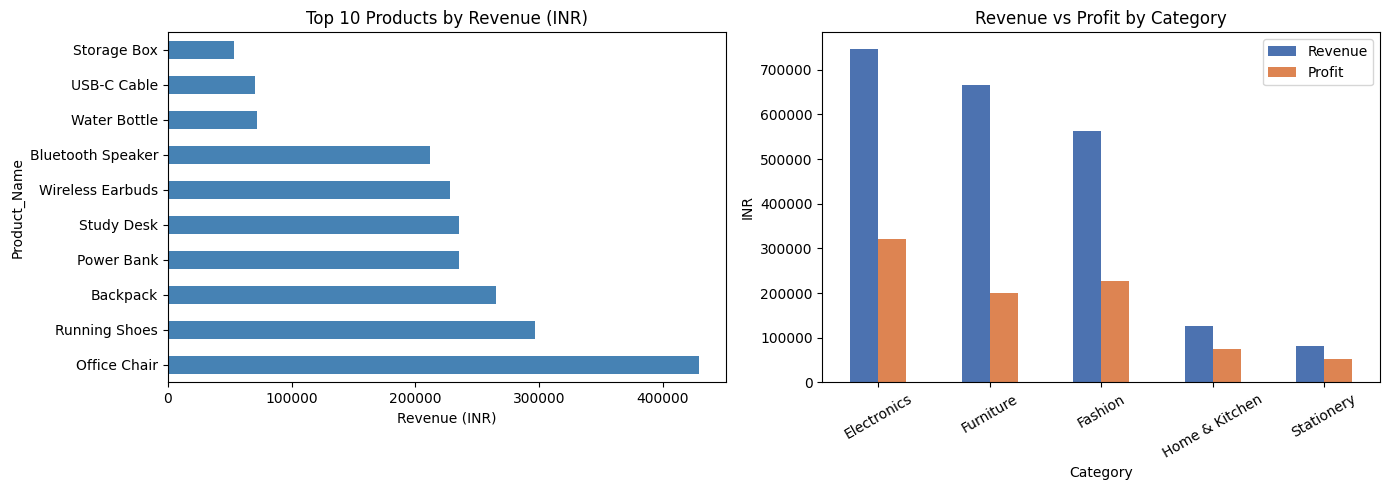

In [12]:
# ============================================================
# PHASE 4 — Q1: Products & Categories by Revenue and Profit
# (self-healing: handles missing columns & whitespace issues)
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- 0. Ensure df is loaded & has 'Category' ---
if 'df' not in globals() or df is None or len(df) == 0:
    df = pd.read_csv('/content/drive/MyDrive/clean_retail.csv')

# Strip hidden whitespace from column names
df.columns = df.columns.str.strip()

# If 'Category' is missing, reload the clean file
if 'Category' not in df.columns:
    print("⚠️  'Category' not found — reloading clean_retail.csv")
    df = pd.read_csv('/content/drive/MyDrive/clean_retail.csv')
    df.columns = df.columns.str.strip()

# If still missing, reload original + re-run minimal cleaning
if 'Category' not in df.columns:
    print("⚠️  Reloading original dataset and re-cleaning")
    df = pd.read_csv('/content/drive/MyDrive/smart_retail_analytics_sales_forecasting_dataset.csv')
    df.columns = df.columns.str.strip()
    df['Order_Date'] = pd.to_datetime(df['Order_Date'], dayfirst=True, errors='coerce')
    df = df.sort_values('Order_Date').reset_index(drop=True)
    df['Year']          = df['Order_Date'].dt.year
    df['Month']         = df['Order_Date'].dt.month
    df['Month_Name']    = df['Order_Date'].dt.strftime('%b')
    df['YearMonth']     = df['Order_Date'].dt.to_period('M').astype(str)
    df['Quarter']       = df['Order_Date'].dt.quarter
    df['Profit_Margin'] = df['Profit_INR'] / df['Revenue_INR']
    df['Discount_Amt']  = df['Quantity'] * df['Unit_Price_INR'] * df['Discount_Pct']
    df.to_csv('/content/drive/MyDrive/clean_retail.csv', index=False)

# Final sanity check
assert 'Category' in df.columns, f"❌ 'Category' still missing. Columns: {df.columns.tolist()}"
print(f"✅ df ready: {df.shape[0]} rows, {df.shape[1]} columns\n")

# ------------------------------------------------------------
# Q1a — Product-level leaderboard
# ------------------------------------------------------------
prod = df.groupby(['Product_Name', 'Category']).agg(
    Revenue=('Revenue_INR', 'sum'),
    Profit=('Profit_INR', 'sum'),
    Units=('Quantity', 'sum'),
    Orders=('Order_ID', 'nunique')
).reset_index().sort_values('Revenue', ascending=False).round(2)

print("=== TOP 10 PRODUCTS BY REVENUE ===")
print(prod.head(10).to_string(index=False))

# ------------------------------------------------------------
# Q1b — Category summary
# ------------------------------------------------------------
cat = df.groupby('Category').agg(
    Revenue=('Revenue_INR', 'sum'),
    Profit=('Profit_INR', 'sum'),
    Orders=('Order_ID', 'nunique')
).round(2).sort_values('Revenue', ascending=False)

cat['Margin_%'] = (cat['Profit'] / cat['Revenue'] * 100).round(2)

print("\n=== CATEGORY PERFORMANCE ===")
print(cat)

# ------------------------------------------------------------
# Visuals
# ------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

prod.head(10).plot.barh(
    x='Product_Name', y='Revenue', ax=ax[0],
    color='steelblue', legend=False
)
ax[0].set_title('Top 10 Products by Revenue (INR)')
ax[0].set_xlabel('Revenue (INR)')

cat[['Revenue', 'Profit']].plot.bar(ax=ax[1], color=['#4C72B0', '#DD8452'])
ax[1].set_title('Revenue vs Profit by Category')
ax[1].set_ylabel('INR')
ax[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

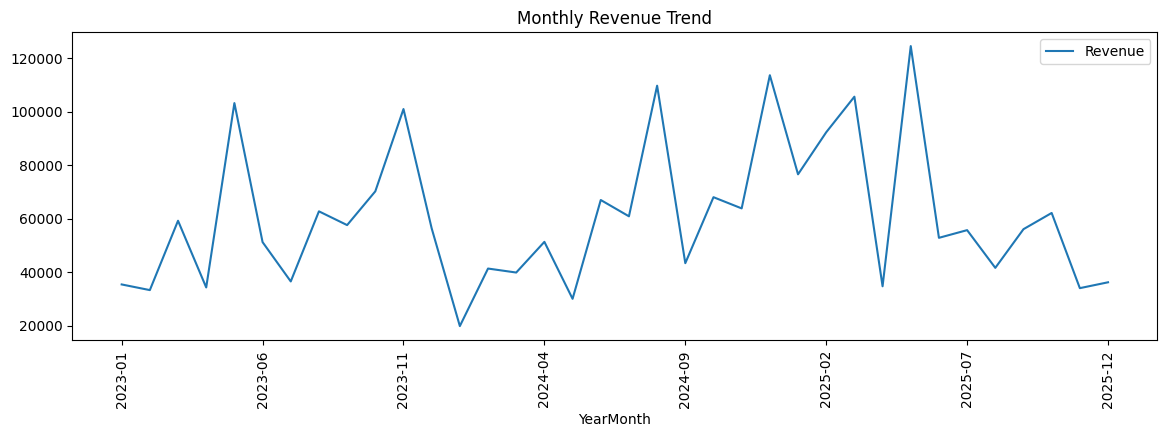

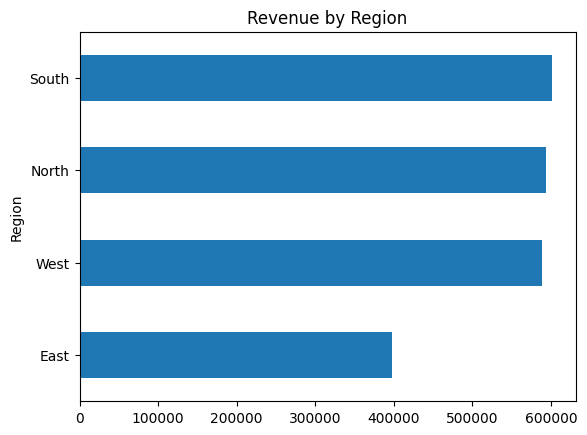

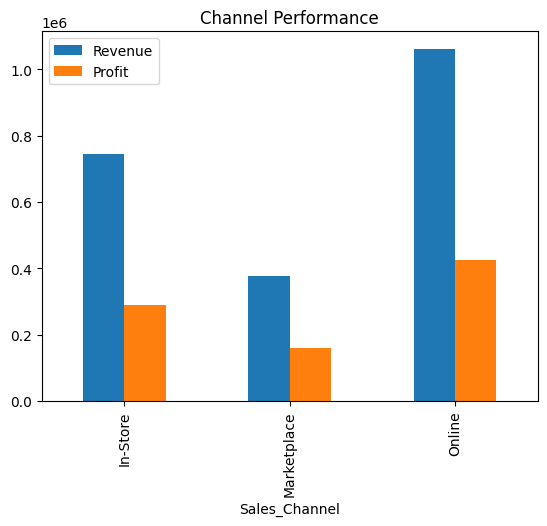

<Axes: xlabel='Month_Name'>

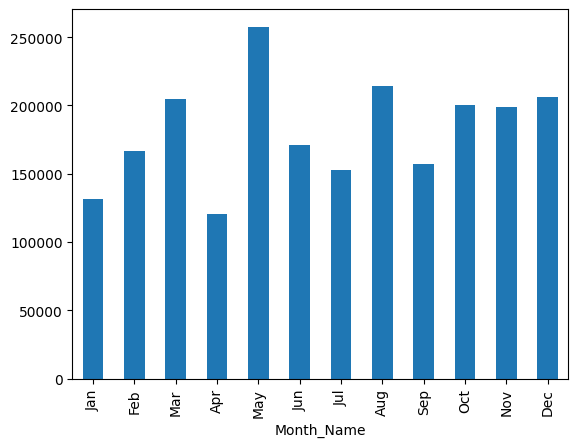

In [13]:
monthly = df.groupby('YearMonth').agg(Revenue=('Revenue_INR','sum'),
                                      Profit=('Profit_INR','sum'),
                                      Orders=('Order_ID','nunique')).reset_index()
monthly.plot(x='YearMonth', y='Revenue', kind='line', figsize=(14,4), title='Monthly Revenue Trend')
plt.xticks(rotation=90); plt.show()

df.groupby('Region')['Revenue_INR'].sum().sort_values().plot.barh(title='Revenue by Region'); plt.show()
df.groupby('Sales_Channel').agg(Revenue=('Revenue_INR','sum'),
                                Profit=('Profit_INR','sum')).plot.bar(title='Channel Performance'); plt.show()

# Seasonality (avg revenue per month across years)
df.groupby('Month_Name')['Revenue_INR'].sum().reindex(
    ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']).plot(kind='bar')

In [14]:
cust = df.groupby(['Customer_ID','Customer_Name']).agg(
    Orders=('Order_ID','nunique'),
    Revenue=('Revenue_INR','sum'),
    Profit=('Profit_INR','sum'),
    Avg_Order=('Revenue_INR','mean'),
    First=('Order_Date','min'),
    Last=('Order_Date','max')).reset_index()
cust['Repeat'] = cust['Orders']>1
cust = cust.sort_values('Revenue', ascending=False)

print("Top 10 customers:\n", cust.head(10))
print("Repeat customer %:", round(cust['Repeat'].mean()*100,1))
print("Revenue share by repeat customers:", round(cust.loc[cust.Repeat,'Revenue'].sum()/cust['Revenue'].sum()*100,1),'%')

# RFM Segmentation (Recency, Frequency, Monetary)
snapshot = df['Order_Date'].max() + pd.Timedelta(days=1)
rfm = df.groupby('Customer_ID').agg(
    Recency=('Order_Date', lambda x:(snapshot-x.max()).days),
    Frequency=('Order_ID','nunique'),
    Monetary=('Revenue_INR','sum'))
rfm['R_Score'] = pd.qcut(rfm['Recency'],4,labels=[4,3,2,1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'),4,labels=[1,2,3,4]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'],4,labels=[1,2,3,4]).astype(int)
rfm['RFM'] = rfm[['R_Score','F_Score','M_Score']].sum(axis=1)
rfm.sort_values('RFM',ascending=False).head(10)

Top 10 customers:
     Customer_ID Customer_Name  Orders   Revenue    Profit    Avg_Order  \
25        C0026  Customer 026       5  48948.35  18918.35  9789.670000   
176       C0180  Customer 180      11  39529.55  17109.55  3593.595455   
170       C0174  Customer 174       6  38041.05  13461.05  6340.175000   
7         C0008  Customer 008       7  35481.95  13586.95  5068.850000   
0         C0001  Customer 001       5  35097.00  10412.00  7019.400000   
80        C0082  Customer 082       4  33655.10  13925.10  8413.775000   
38        C0040  Customer 040       5  31175.75  12230.75  6235.150000   
51        C0053  Customer 053       8  30966.80  12381.80  3870.850000   
122       C0126  Customer 126       7  30076.05  10811.05  4296.578571   
172       C0176  Customer 176       4  30007.45  11017.45  7501.862500   

         First       Last  Repeat  
25  2023-10-05 2025-04-10    True  
176 2023-07-04 2025-11-07    True  
170 2023-01-09 2025-12-10    True  
7   2023-02-07 2025-07

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM
Customer_ID,,,,,,,
C0019,92,8,24183.25,4,4,4,12
C0180,36,11,39529.55,4,4,4,12
C0119,8,6,24549.30,4,4,4,12
C0134,63,6,20623.00,4,4,4,12
C0174,3,6,38041.05,4,4,4,12
C0083,92,6,26847.80,4,4,4,12
C0126,3,7,30076.05,4,4,4,12
C0084,41,6,22326.00,4,4,4,12
C0014,7,6,16379.25,4,4,3,11


In [15]:
# (a) Trend per product – compare last 6 months vs previous 6 months
df_prod_month = df.groupby(['Product_Name','YearMonth'])['Revenue_INR'].sum().reset_index()
cutoff = df['Order_Date'].max() - pd.DateOffset(months=6)
recent = df[df.Order_Date>=cutoff].groupby('Product_Name')['Revenue_INR'].sum()
prev   = df[df.Order_Date< cutoff].groupby('Product_Name')['Revenue_INR'].sum()
trend  = pd.DataFrame({'Prev6M':prev,'Last6M':recent}).fillna(0)
trend['Growth_%'] = (trend['Last6M']-trend['Prev6M'])/trend['Prev6M'].replace(0,np.nan)*100
print("Declining products:\n", trend.sort_values('Growth_%').head(5))

# (b) Stock risk – current stock vs reorder level
stock = df.groupby(['Product_Name'])[['Stock_On_Hand','Reorder_Level']].last()
stock['Stock_Ratio'] = stock['Stock_On_Hand']/stock['Reorder_Level']
stock['Risk'] = np.where(stock['Stock_Ratio']<1,'CRITICAL',
                  np.where(stock['Stock_Ratio']<2,'LOW','OK'))
print(stock.sort_values('Stock_Ratio'))

# (c) Demand vs stock: units sold last 30 days vs stock
last30 = df[df.Order_Date>=df.Order_Date.max()-pd.Timedelta(days=30)].groupby('Product_Name')['Quantity'].sum()
stock['Sold_30d'] = last30
stock['Days_Cover'] = stock['Stock_On_Hand'] / (stock['Sold_30d']/30).replace(0,np.nan)
print(stock.sort_values('Days_Cover').head())

Declining products:
                  Prev6M    Last6M   Growth_%
Product_Name                                
Office Chair  407475.90  21996.00 -94.601889
Power Bank    223500.90  12216.85 -94.533870
Study Desk    220772.40  14398.20 -93.478261
Gel Pen Set    34441.35   5133.05 -85.096258
USB-C Cable    60711.95   9373.65 -84.560453
                   Stock_On_Hand  Reorder_Level  Stock_Ratio Risk
Product_Name                                                     
Study Desk                    18              5     3.600000   OK
Running Shoes                 63             13     4.846154   OK
Storage Box                   97             20     4.850000   OK
Office Chair                  34              7     4.857143   OK
Bluetooth Speaker             73             15     4.866667   OK
Power Bank                    88             18     4.888889   OK
USB-C Cable                  296             60     4.933333   OK
Backpack                      79             16     4.937500   OK
Wire

In [16]:
conn = sqlite3.connect('retail.db')
df.to_sql('sales', conn, if_exists='replace', index=False)
q = lambda s: pd.read_sql_query(s, conn)

# Q1 – Category revenue & profit
q("""
SELECT Category,
       ROUND(SUM(Revenue_INR),2) AS Revenue,
       ROUND(SUM(Profit_INR),2)  AS Profit,
       ROUND(SUM(Profit_INR)*100.0/SUM(Revenue_INR),2) AS Margin_Pct
FROM sales GROUP BY Category ORDER BY Revenue DESC;
""")

# Q2 – Region × Channel matrix
q("""
SELECT Region, Sales_Channel,
       ROUND(SUM(Revenue_INR),2) Revenue,
       COUNT(DISTINCT Order_ID) Orders
FROM sales GROUP BY Region, Sales_Channel
ORDER BY Revenue DESC;
""")

# Q3 – Top 10 customers by lifetime value
q("""
SELECT Customer_ID, Customer_Name,
       COUNT(DISTINCT Order_ID) Orders,
       ROUND(SUM(Revenue_INR),2) Lifetime_Value
FROM sales GROUP BY Customer_ID ORDER BY Lifetime_Value DESC LIMIT 10;
""")

# Q4 – Stock alerts
q("""
SELECT Product_Name, Stock_On_Hand, Reorder_Level,
       ROUND(Stock_On_Hand*1.0/Reorder_Level,2) AS Ratio
FROM sales GROUP BY Product_Name
HAVING Stock_On_Hand <= Reorder_Level*1.5
ORDER BY Ratio;
""")

# Q5 – Monthly totals for forecasting export
monthly_sql = q("""
SELECT substr(Order_Date,7,4)||'-'||substr(Order_Date,4,2) AS Month,  -- if dates stored as text
       ROUND(SUM(Revenue_INR),2) Revenue
FROM sales GROUP BY Month ORDER BY Month;
""")

In [17]:
df.to_csv('/content/drive/MyDrive/retail_for_powerbi.csv', index=False)
monthly.to_csv('/content/drive/MyDrive/monthly_kpis.csv', index=False)
stock.reset_index().to_csv('/content/drive/MyDrive/stock_risk.csv', index=False)

Train: 2023-01-01 00:00:00 → 2025-06-01 00:00:00 | Test: 2025-07-01 00:00:00 → 2025-12-01 00:00:00


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


Naive          MAE=      10,345  RMSE=      11,983  MAPE=25.7%
3M-MA          MAE=      23,065  RMSE=      25,465  MAPE=56.7%
SARIMA         MAE=      60,357  RMSE=      70,429  MAPE=142.7%
Holt-Winters   MAE=      41,188  RMSE=      48,471  MAPE=103.4%
RandomForest   MAE=      43,213  RMSE=      44,503  MAPE=100.9%


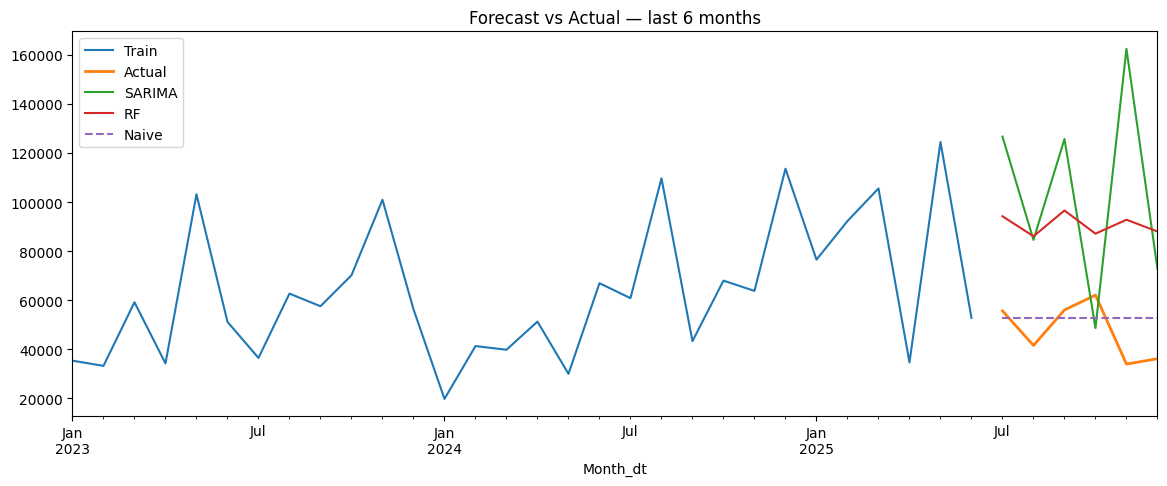

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


            Forecast    Lower     Upper
2026-01-01   46039.0 -47791.0  139869.0
2026-02-01   60320.0 -33938.0  154577.0
2026-03-01   38911.0 -79135.0  156957.0
2026-04-01   96518.0 -21853.0  214889.0
2026-05-01   34654.0 -96845.0  166152.0
2026-06-01   87903.0 -45033.0  220839.0


In [18]:
# 7.1 Build monthly series (use full history)
monthly['Month_dt'] = pd.to_datetime(monthly['YearMonth'])
series = monthly.set_index('Month_dt')['Revenue'].asfreq('MS')

# 7.2 Train/test split — last 6 months as test
train, test = series[:-6], series[-6:]
print("Train:", train.index.min(), "→", train.index.max(), "| Test:", test.index.min(), "→", test.index.max())

# 7.3 BASELINE 1: Naive (last value carried forward)
naive = pd.Series(train.iloc[-1], index=test.index)

# 7.4 BASELINE 2: 3-month moving average
ma = pd.Series(train.iloc[-3:].mean(), index=test.index)

# 7.5 MODEL 1: SARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
sarima = SARIMAX(train, order=(1,1,1), seasonal_order=(1,1,1,12),
                 enforce_stationarity=False).fit(disp=False)
sar_pred = sarima.predict(start=test.index[0], end=test.index[-1])

# 7.6 MODEL 2: Holt-Winters (simpler alternative)
from statsmodels.tsa.holtwinters import ExponentialSmoothing
hw = ExponentialSmoothing(train, trend='add', seasonal='add', seasonal_periods=12).fit()
hw_pred = hw.predict(start=test.index[0], end=test.index[-1])

# 7.7 MODEL 3: Random Forest on engineered features (optional)
feat = monthly.copy()
feat['Month_dt']=pd.to_datetime(feat['YearMonth'])
feat['t']    = np.arange(len(feat))
feat['sin']  = np.sin(2*np.pi*feat['Month_dt'].dt.month/12)
feat['cos']  = np.cos(2*np.pi*feat['Month_dt'].dt.month/12)
feat['lag1'] = feat['Revenue'].shift(1)
feat['lag12']= feat['Revenue'].shift(12)
feat = feat.dropna()
tr, te = feat.iloc[:-6], feat.iloc[-6:]
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=300, random_state=42).fit(
        tr[['t','sin','cos','lag1','lag12']], tr['Revenue'])
rf_pred = pd.Series(rf.predict(te[['t','sin','cos','lag1','lag12']]), index=test.index)

# 7.8 Evaluate
from sklearn.metrics import mean_absolute_error, mean_squared_error
def mape(a,b): return np.mean(np.abs((a-b)/a))*100
for name, p in [('Naive',naive),('3M-MA',ma),('SARIMA',sar_pred),
                ('Holt-Winters',hw_pred),('RandomForest',rf_pred)]:
    print(f"{name:14s} MAE={mean_absolute_error(test,p):>12,.0f}  "
          f"RMSE={np.sqrt(mean_squared_error(test,p)):>12,.0f}  MAPE={mape(test,p):.1f}%")

# 7.9 Plot comparison
plt.figure(figsize=(14,5))
train.plot(label='Train'); test.plot(label='Actual', lw=2)
sar_pred.plot(label='SARIMA'); rf_pred.plot(label='RF'); naive.plot(label='Naive', ls='--')
plt.legend(); plt.title('Forecast vs Actual — last 6 months'); plt.show()

# 7.10 Refit best model on FULL data → 6-month forward forecast
final = SARIMAX(series, order=(1,1,1), seasonal_order=(1,1,1,12),
                enforce_stationarity=False).fit(disp=False)
future = final.get_forecast(steps=6)
fc = future.predicted_mean
ci = future.conf_int()
print(pd.DataFrame({'Forecast':fc.round(0),
                    'Lower':ci.iloc[:,0].round(0),
                    'Upper':ci.iloc[:,1].round(0)}))
fc.to_csv('/content/drive/MyDrive/forecast_next6.csv')

In [19]:
import pandas as pd

# Reload the cleaned file from your Drive
df = pd.read_csv('/content/drive/MyDrive/clean_retail.csv')
df.columns = df.columns.str.strip()
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
print(df.shape)   # should print (2002, 29) or similar

(734, 27)


In [20]:
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Latest stock per product (last row for each product)
# ------------------------------------------------------------
latest = (df.sort_values('Order_Date')
            .groupby('Product_Name')
            .agg(Stock_On_Hand=('Stock_On_Hand', 'last'),
                 Reorder_Level=('Reorder_Level', 'last'))
            .reset_index())

# ------------------------------------------------------------
# 2. Units sold in the last 30 days (to compute days of cover)
# ------------------------------------------------------------
cutoff = df['Order_Date'].max() - pd.Timedelta(days=30)
sold_30d = (df[df['Order_Date'] >= cutoff]
              .groupby('Product_Name')['Quantity']
              .sum()
              .reset_index()
              .rename(columns={'Quantity': 'Sold_30d'}))

# ------------------------------------------------------------
# 3. Merge and calculate ratios
# ------------------------------------------------------------
stock_risk = latest.merge(sold_30d, on='Product_Name', how='left')
stock_risk['Sold_30d']     = stock_risk['Sold_30d'].fillna(0)
stock_risk['Stock_Ratio']  = (stock_risk['Stock_On_Hand'] /
                              stock_risk['Reorder_Level']).round(2)
stock_risk['Days_Of_Cover'] = (stock_risk['Stock_On_Hand'] /
                               (stock_risk['Sold_30d'] / 30).replace(0, np.nan)
                              ).round(1)

# ------------------------------------------------------------
# 4. Status label (CRITICAL / LOW / OK)
# ------------------------------------------------------------
stock_risk['Status'] = np.where(stock_risk['Stock_Ratio'] < 1.0,  'CRITICAL',
                        np.where(stock_risk['Stock_Ratio'] < 1.5,  'LOW',
                                                                   'OK'))

# ------------------------------------------------------------
# 5. Sort by risk (lowest stock ratio first = highest risk)
# ------------------------------------------------------------
stock_risk = stock_risk.sort_values('Stock_Ratio').reset_index(drop=True)

# ------------------------------------------------------------
# 6. Show and save
# ------------------------------------------------------------
print(stock_risk)
print("\nColumns:", stock_risk.columns.tolist())
print("Status counts:\n", stock_risk['Status'].value_counts())

stock_risk.to_csv('/content/drive/MyDrive/stock_risk.csv', index=False)
print("\n✅ Saved: /content/drive/MyDrive/stock_risk.csv")

         Product_Name  Stock_On_Hand  Reorder_Level  Sold_30d  Stock_Ratio  \
0          Study Desk             18              5       1.0         3.60   
1       Running Shoes             63             13       0.0         4.85   
2         Storage Box             97             20       0.0         4.85   
3        Office Chair             34              7       0.0         4.86   
4   Bluetooth Speaker             73             15       2.0         4.87   
5          Power Bank             88             18       0.0         4.89   
6         USB-C Cable            296             60       8.0         4.93   
7            Backpack             79             16       0.0         4.94   
8    Wireless Earbuds            119             24      17.0         4.96   
9        Water Bottle            179             36       6.0         4.97   
10      Notebook Pack            249             50       7.0         4.98   
11        Gel Pen Set            399             80      15.0   

In [21]:
import os
print(os.listdir('/content/drive/MyDrive/'))

['Colab Notebooks', 'Classroom', 'Documents ', ' photos', 'face_mat_open (1).ipynb', 'assignment_3.docx', '223055_ADS Assignment 2.docx.pdf', 'STRESS MANAGEMENT 1.pdf', 'stress management 2.pdf', 'assignment_1.pdf', 'assignment _2.pdf', 'assignment_4 (1).pdf', 'assignment_4.pdf', 'ads assign.pdf', 'assignment 6.pdf', 'assignment 5.pdf', 'assignment 4.pdf', 'ADS_Assignment_07.docx', 'ADS- Application of Hash Table in Merkle Tree .pptx', 'Theory of Computation Sem II Pattern 2020 Endsem Exam May 2023_Computer.pdf', 'Theory of Computation Sem II Pattern 2020 Endsem Exam May 2023_Computer.gdoc', 'archive (9).zip', 'Churn_Modelling (1).csv', 'Churn_Modelling.csv', 'SEPM ppt (1).gslides', 'SEPM ppt.gslides', 'Untitled document.gdoc', 'Untitled document.docx', 'literature survey.docx', 'Copy of 321026_22210497_SEPM_SRS.pdf', 'Rushabh Shrirame-CCNAv7 Introduct-certificate (2).gdoc', 'Rushabh Shrirame-Introduction to -certificate (2).gdoc', 'Parthsarthi Wange CCNAv7 Introduct-certificate (2).gd

In [22]:
import pandas as pd
import numpy as np
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Load your original dataset
df = pd.read_csv(
    "/content/smart_retail_analytics_sales_forecasting_dataset.csv"
)

df["Order_Date"] = pd.to_datetime(df["Order_Date"])

# Aggregate revenue by month
monthly_sales = (
    df.set_index("Order_Date")["Revenue_INR"]
      .resample("MS")
      .sum()
      .asfreq("MS", fill_value=0)
)

# Train the forecasting model
model = ExponentialSmoothing(
    monthly_sales,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
)

fitted_model = model.fit(optimized=True)

# Forecast the next three months
forecast = fitted_model.forecast(3)

forecast_df = pd.DataFrame({
    "Month": forecast.index,
    "Forecast_Revenue_INR": np.maximum(forecast.values, 0)
})

forecast_df["Month"] = forecast_df["Month"].dt.strftime("%Y-%m-%d")

print("Next three months forecast:")
display(forecast_df.round(2))

# Export forecast results
forecast_df.to_csv(
    "/content/sales_forecast.csv",
    index=False
)

# Export historical monthly sales
historical_df = monthly_sales.rename(
    "Actual_Revenue_INR"
).reset_index()

historical_df.to_csv(
    "/content/monthly_sales.csv",
    index=False
)

print("Forecast and historical monthly sales exported.")

Next three months forecast:


,Month,Forecast_Revenue_INR
0,2026-01-01,161341.20
1,2026-02-01,151099.02
2,2026-03-01,143719.76


Forecast and historical monthly sales exported.


In [23]:
from google.colab import files

files.download('/content/sales_forecast.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
queries_text = """-- ============================================================
-- Smart Retail Analytics — SQL Business Queries
-- Database: retail.db (SQLite) with tables: sales, customers, products
-- ============================================================

-- Q1: Product & Category Revenue / Profit
SELECT Product_Name, Category,
       COUNT(DISTINCT Order_ID) AS Orders,
       SUM(Quantity) AS Units_Sold,
       ROUND(SUM(Revenue_INR), 2) AS Total_Revenue,
       ROUND(SUM(Profit_INR), 2)  AS Total_Profit
FROM sales
GROUP BY Product_Name, Category
ORDER BY Total_Revenue DESC;

-- Q1b: Category summary
SELECT Category,
       ROUND(SUM(Revenue_INR), 2) AS Revenue,
       ROUND(SUM(Profit_INR), 2)  AS Profit
FROM sales
GROUP BY Category
ORDER BY Revenue DESC;

-- Q2a: Monthly trend
SELECT YearMonth,
       COUNT(DISTINCT Order_ID) AS Orders,
       ROUND(SUM(Revenue_INR), 2) AS Revenue
FROM sales
GROUP BY YearMonth
ORDER BY YearMonth;

-- Q2b: Region performance
SELECT Region,
       COUNT(DISTINCT Order_ID) AS Orders,
       ROUND(SUM(Revenue_INR), 2) AS Revenue
FROM sales
GROUP BY Region
ORDER BY Revenue DESC;

-- Q2c: Channel performance
SELECT Sales_Channel,
       COUNT(DISTINCT Order_ID) AS Orders,
       ROUND(SUM(Revenue_INR), 2) AS Revenue,
       ROUND(AVG(Revenue_INR), 2) AS AOV
FROM sales
GROUP BY Sales_Channel
ORDER BY Revenue DESC;

-- Q3: Top 10 customers by lifetime value
SELECT Customer_ID, Customer_Name,
       COUNT(DISTINCT Order_ID) AS Orders,
       ROUND(SUM(Revenue_INR), 2) AS Lifetime_Value
FROM sales
GROUP BY Customer_ID, Customer_Name
ORDER BY Lifetime_Value DESC
LIMIT 10;

-- Q4: Stock alerts
WITH latest AS (
  SELECT Product_Name, Stock_On_Hand, Reorder_Level,
         ROW_NUMBER() OVER (PARTITION BY Product_Name ORDER BY Order_Date DESC) AS rn
  FROM sales
)
SELECT Product_Name, Stock_On_Hand, Reorder_Level,
       ROUND(Stock_On_Hand * 1.0 / Reorder_Level, 2) AS Stock_Ratio,
       CASE WHEN Stock_On_Hand < Reorder_Level THEN 'CRITICAL'
            WHEN Stock_On_Hand < Reorder_Level * 1.5 THEN 'LOW'
            ELSE 'OK' END AS Status
FROM latest
WHERE rn = 1
ORDER BY Stock_Ratio ASC;

-- Q5: Monthly series for forecasting
SELECT YearMonth,
       ROUND(SUM(Revenue_INR), 2) AS Revenue
FROM sales
GROUP BY YearMonth
ORDER BY YearMonth;
"""

with open('/content/drive/MyDrive/queries.sql', 'w') as f:
    f.write(queries_text)
print("✅ Saved /content/drive/MyDrive/queries.sql")

from google.colab import files
files.download('/content/drive/MyDrive/queries.sql')

✅ Saved /content/drive/MyDrive/queries.sql


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
import os, shutil
base = '/content/drive/MyDrive'
required = [
    'clean_retail.csv',
    'retail_for_powerbi.csv',
    'monthly_kpis.csv',
    'stock_risk.csv',
    'forecast_next6.csv',
]
for f in required:
    p = f'{base}/{f}'
    print(f"{'✅' if os.path.exists(p) else '❌'} {f}")

✅ clean_retail.csv
✅ retail_for_powerbi.csv
✅ monthly_kpis.csv
✅ stock_risk.csv
✅ forecast_next6.csv
